# MetricSuite Tutorial: Statistics on Fake Data

This notebook shows the `MetricSuite` statistics workflow from start to finish on
generated data, so every step runs in seconds and the true effects are known in
advance:

- **Part 1 -- Register**: put research outputs into a suite, tagged with the labels
  you'll later group, pair, and filter by.
- **Part 2 -- Test**: run a paired comparison, read the result, test against an
  offset, and estimate the size of the difference.
- **Part 3 -- Plot**: draw the results with their statistics.
- **Part 4 -- Save, load, verify**: persist the data and each result, reload
  them, and check that a result really came from a given suite's data.

The design to keep in mind: **the suite holds the data and computes; a result holds
the output and every setting that produced it** (test, offset, alternative,
correction, alpha, and a `data_key` fingerprint of the exact rows it used). Results
never keep a reference to the suite, so they can be saved, shared, and reloaded on
their own -- and `suite.verify(result)` tells you whether a result matches a suite's
data.

For the same workflow on a real study (plus normality, ANOVA, and cluster
permutation), see `metricsuite-noisesweep.ipynb`.

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import mindmap as mm
from mindmap.metric import MetricSuite
from mindmap.metric.results import EstimateResult, PairwiseResult

COLORS = {
    "new":      "#2a78d6",  # blue
    "baseline": "#1baf7a",  # aqua
    "legacy":   "#e34948",  # red
}

## 🧪 - Part 1: Registering research outputs

### The fake study

Three methods (`new`, `baseline`, `legacy`) are each run 3 times on 20 subjects, and
every run produces two outputs:

- `accuracy`, higher is better. True means: `new` 0.78, `baseline` 0.76,
  `legacy` 0.70 -- so `new` beats `baseline` by a little and `legacy` by a lot.
- `error_mm`, a positive, right-skewed localization error, lower is better.

Each subject has its own difficulty (shared by every method), which is what makes a
*paired* test, matched by subject, much more sensitive than comparing pooled
groups.

In [2]:
TRUE_ACCURACY = {"new": 0.78, "baseline": 0.76, "legacy": 0.70}
N_SUBJECTS, N_RUNS = 20, 3


def make_study(seed, name):
    rng = np.random.default_rng(seed)
    suite = MetricSuite(name=name)
    for s in range(N_SUBJECTS):
        subject = f"sub-{s:02d}"
        difficulty = rng.normal(0, 0.06)              # shared by every method
        for method, mu in TRUE_ACCURACY.items():
            skill = mu + difficulty + rng.normal(0, 0.02)  # subject x method
            for run in range(N_RUNS):
                acc = np.clip(skill + rng.normal(0, 0.03), 0, 1)
                err = rng.lognormal(np.log(60 * (1 - acc)), 0.3)
                suite.register("accuracy", acc, method=method, subject=subject, run=run)
                suite.register("error_mm", err, method=method, subject=subject, run=run)
    return suite


suite = make_study(seed=0, name="Fake study")

### What `register` does

`suite.register(metric, values, **coords)` adds one output for one metric. Every
keyword is a free-form tag: there is no fixed "group" or "subject" argument. Here
`method`, `subject`, and `run` are just names we chose; later, each test is told
which tag holds the groups (`group_by="method"`), which holds the matching unit
(`pairing_col="subject"`), and which holds repeated runs (`unit_col="run"`).

`values` can also be a curve (1D array) or a stack of repeated curves (2D array),
with point-wise coords such as `times=` -- see the `register` docstring. Here every
output is a single number.

`.describe()` shows what's in the suite, and `.summary()` the numbers per group.

In [3]:
suite.describe()

,Metric,Coord,Kind,N unique,Detail
0,accuracy,method,categorical,3,"baseline, legacy, new"
1,accuracy,subject,categorical,20,"sub-00, sub-01, sub-02, sub-03, sub-04, sub-05..."
2,accuracy,run,numerical,3,"[0, 2]"
3,error_mm,method,categorical,3,"baseline, legacy, new"
4,error_mm,subject,categorical,20,"sub-00, sub-01, sub-02, sub-03, sub-04, sub-05..."
5,error_mm,run,numerical,3,"[0, 2]"


In [4]:
suite.summary("accuracy", group_by="method")

,method,mean,std,count
0,baseline,0.753847,0.063471,60
1,legacy,0.689274,0.060846,60
2,new,0.781408,0.063904,60


In [5]:
suite.to_df(metrics="accuracy").head()

,Metric,Value,method,subject,run
0,accuracy,0.804114,new,sub-00,0
2,accuracy,0.768832,new,sub-00,1
4,accuracy,0.824022,new,sub-00,2
6,accuracy,0.715506,baseline,sub-00,0
8,accuracy,0.754709,baseline,sub-00,1


## 🔬 - Part 2: Performing a test

### A paired Wilcoxon test

`suite.stat.wilcoxon` compares groups pair by pair, matched by subject:

- `comparisons`: which pairs to test. `build_comparisons("new", [...])` makes the
  usual "one reference vs. every competitor" list.
- `pairing_col="subject"`: the matching unit -- `new` and `baseline` are compared
  subject by subject.
- `unit_col="run"`: the 3 runs of each subject are averaged first, so they count as
  one subject, not 3 independent observations.
- `correction="fdr_bh"` (default): the p-values of both pairs are corrected as one
  family. `"holm"`, `"bonferroni"`, and `"fdr_by"` are also available.
- `effect_sizes`: which effect sizes to report (next section).

In [6]:
comparisons = suite.stat.build_comparisons("new", ["baseline", "legacy"])

acc = suite.stat.wilcoxon(
    "accuracy", group_by="method", comparisons=comparisons,
    pairing_col="subject", unit_col="run",
    effect_sizes=("rank_biserial", "hodges_lehmann"),
)
acc

PairwiseResult(metric='accuracy', test='wilcoxon', correction='fdr_bh', alpha=0.05, n_comparisons=2)
  new vs baseline: p=0.0003223*, rank_biserial=0.848, hodges_lehmann=0.0268, n=20
  new vs legacy: p=3.815e-06*, rank_biserial=1, hodges_lehmann=0.096, n=20

### Effect sizes

An effect size says *how large* a difference is. Two kinds:

- **standardized** (unitless): rank-biserial `r`, Cohen's `dz`/`d`, Hedges' `g`,
  CLES -- comparable across metrics;
- **unstandardized** (in the metric's units): the mean difference and the
  Hodges-Lehmann estimate (the median difference that goes with the Wilcoxon test)
  -- what a reader needs to judge whether the gain matters.

Each test allows the effect sizes that match it, and reports the ones you ask for
with `effect_sizes=` (by default only the first, standardized one):

In [7]:
PairwiseResult.EFFECT_SIZES

{'wilcoxon': ('rank_biserial', 'hodges_lehmann'),
 'mcnemar': ('prop_diff', 'odds_ratio'),
 'paired_ttest': ('cohens_dz', 'hedges_gz', 'mean_diff'),
 'ttest_ess': ('cohens_dz', 'hedges_gz', 'mean_diff'),
 'ttest': ('cohens_d', 'hedges_g', 'mean_diff'),
 'mannwhitneyu': ('rank_biserial', 'cles', 'hodges_lehmann')}

Each requested effect size becomes a column of `acc.table`, next to the test
statistic and the raw and corrected p-values:

In [8]:
acc.table

,group_a,group_b,n_pairs,n_zero,n_a,n_b,statistic,p_value,n_eff,p_corrected,significant,rank_biserial,hodges_lehmann
0,new,baseline,20,0,20,20,16.0,0.000322,NaN,0.000322,True,0.847619,0.026838
1,new,legacy,20,0,20,20,0.0,0.000002,NaN,0.000004,True,1.000000,0.096022


The result also carries every setting that produced it, so it can be read (or
reproduced) without the suite:

In [9]:
{k: getattr(acc, k) for k in ["metric", "test", "group_by", "pairing_col", "unit_col",
                                "effect_sizes", "offset", "alternative", "correction", "alpha", "data_key"]}

{'metric': 'accuracy',
 'test': 'wilcoxon',
 'group_by': 'method',
 'pairing_col': 'subject',
 'unit_col': 'run',
 'effect_sizes': ('rank_biserial', 'hodges_lehmann'),
 'offset': 0.0,
 'alternative': 'two-sided',
 'correction': 'fdr_bh',
 'alpha': 0.05,
 'data_key': 'fc7c6bbeda290399'}

`.vs(reference)` is the compact view for "one reference vs. everything":
every effect size oriented so that **positive = reference better**, whichever way
each pair was stored.

In [10]:
acc.vs("new")

,p_value,p_corrected,significant,rank_biserial,hodges_lehmann,offset,alternative,n_pairs,n_zero
method,,,,,,,,,
baseline,0.000322,0.000322,True,0.847619,0.026838,0.0,two-sided,20,0
legacy,0.000002,0.000004,True,1.000000,0.096022,0.0,two-sided,20,0


For a lower-is-better metric, pass `higher_is_better=False` and the
orientation flips, so positive still means "reference better" -- here, a positive
Hodges-Lehmann value is an error *reduction* in mm:

In [11]:
err = suite.stat.wilcoxon(
    "error_mm", group_by="method", comparisons=comparisons,
    pairing_col="subject", unit_col="run",
    effect_sizes=("rank_biserial", "hodges_lehmann"),
)
err.vs("new", higher_is_better=False)

,p_value,p_corrected,significant,rank_biserial,hodges_lehmann,offset,alternative,n_pairs,n_zero
method,,,,,,,,,
baseline,0.728506,0.728506,False,-0.095238,-0.364861,0.0,two-sided,20,0
legacy,0.000261,0.000523,True,0.857143,6.209770,0.0,two-sided,20,0


### Testing against an offset

"Is `new` better at all?" is often not the interesting question; "is it better by
more than 0.05 accuracy?" is. `offset=0.05` tests `new - competitor` against 0.05
instead of 0. With an offset, the test is one-sided (`alternative="greater"` by
default).

**The offset only changes the p-value.** The effect sizes still describe the raw
difference, so the Hodges-Lehmann estimate can be read directly against the
offset -- above 0.05 for `legacy`, below it for `baseline`.

Here we also switch to Holm's correction. True differences are 0.02 (`baseline`)
and 0.08 (`legacy`), so only `legacy` should clear the bar.

In [12]:
acc_margin = suite.stat.wilcoxon(
    "accuracy", group_by="method", comparisons=comparisons,
    pairing_col="subject", unit_col="run",
    offset=0.05, correction="holm",
    effect_sizes=("rank_biserial", "hodges_lehmann"),
)
acc_margin.vs("new")

,p_value,p_corrected,significant,rank_biserial,hodges_lehmann,offset,alternative,n_pairs,n_zero
method,,,,,,,,,
baseline,0.998644,0.998644,False,0.847619,0.026838,0.05,greater,20,0
legacy,0.000131,0.000261,True,1.000000,0.096022,0.05,greater,20,0


### Estimates: effect sizes with confidence intervals

Every effect size is an *estimate* of a population quantity, so each one is also
available on its own through `suite.estimate.<name>` -- computed by the same
function the tests use, so the numbers agree:

| | per group | per pair |
|---|---|---|
| unstandardized | `mean`, `median`, `proportion` (0/1) | `mean_diff`, `hodges_lehmann`, `prop_diff` (0/1) |
| standardized | | `rank_biserial`, `cohens_dz`, `hedges_gz`, `cohens_d`, `hedges_g`, `cles`, `odds_ratio` (0/1) |

What an estimate adds is a **confidence interval** (`ci=True`, the default).
Intervals exist for `mean` (t), `median` (exact binomial), `proportion` (Wilson),
`mean_diff` (t), `hodges_lehmann` (signed-rank), `prop_diff` (Newcombe) and
`odds_ratio` (exact); for the other standardized ones none is implemented yet, so
ask for the point value with `ci=False`. The 0/1 estimates go with
`suite.stat.mcnemar`, the paired test for a binary outcome.

`suite.estimate.from_result(acc)` reuses everything the test used (same pairs,
pairing, runs averaged, filters), so the interval describes exactly the data the
p-value came from. Its default estimator is the test's unstandardized effect size
-- Hodges-Lehmann for a Wilcoxon test:

In [13]:
hl = suite.estimate.from_result(acc)
hl

EstimateResult(metric='accuracy', estimator='hodges_lehmann', ci=95%, n_rows=2)
  new vs baseline: 0.02684 [0.01283, 0.0419]
  new vs legacy: 0.09602 [0.07391, 0.1109]

In [14]:
hl.vs("new")

,estimate,ci_low,ci_high,n_reference,n_competitor
method,,,,,
baseline,0.026838,0.012825,0.041904,20,20
legacy,0.096022,0.073912,0.110892,20,20


The intervals tell the same story as the offset test: the `legacy` interval sits
entirely above 0.05, the `baseline` one entirely below it.

A standardized effect size without an interval needs `ci=False`:

In [15]:
try:
    suite.estimate.rank_biserial("accuracy", group_by="method", comparisons=comparisons, pairing_col="subject", unit_col="run")
except NotImplementedError as e:
    print(e)

suite.estimate.rank_biserial(
    "accuracy", group_by="method", comparisons=comparisons, pairing_col="subject", unit_col="run", ci=False,
).vs("new")

No confidence interval is implemented for 'rank_biserial' yet -- pass ci=False for its point value.


,estimate,ci_low,ci_high,n_reference,n_competitor
method,,,,,
baseline,0.847619,NaN,NaN,20,20
legacy,1.000000,NaN,NaN,20,20


And per group -- e.g. the median accuracy of each method, with a 95% interval:

In [16]:
suite.estimate.median("accuracy", group_by="method").table

,group,estimate,ci_low,ci_high,n,ci_method
0,baseline,0.747425,0.715771,0.776250,60,binomial_exact
1,legacy,0.689291,0.665526,0.712502,60,binomial_exact
2,new,0.776344,0.758621,0.793275,60,binomial_exact


## 📊 - Part 3: Plotting results with statistics

`suite.plot` makes premade figures from the suite's own numbers: the points,
centers and intervals are computed by the suite (the same functions as
`suite.stat` / `suite.estimate`), then drawn with plain matplotlib. Two families:

| family | methods | take | show |
|---|---|---|---|
| data plots | `box`, `violin`, `bar`, `point`, `strip`, `line`, `scatter`, `distribution`, `histogram` | a metric name | the data, no test |
| stat plots | `group_comparison`, `paired_differences`, `estimate`, `anova`, `normality_test`, `cluster_permutation` | a result | what that result tested |

A stat plot's name says which view of the result it draws -- the groups, the
per-unit differences that were tested, or the effect with its interval -- and its
shape follows the result (e.g. `paired_differences` draws one column per competitor
for a Wilcoxon result, one curve per competitor for a cluster-permutation result).
By default a stat plot draws the summary that matches the test (`center="auto"`):
medians for a Wilcoxon test, means for a t-test, proportions for McNemar.

Every method takes the same argument names for the same things -- variables (`x`,
`hue`, `unit`), estimates (`center`, `interval`), text (`labels`, `xlabel`,
`ylabel`, `title`, `legend`, `annotate`), colors (`palette`, `fill_alpha`), and
one `*_kws` dict per drawn layer for anything else. Layout is yours: pass `ax=` to
draw into your own subplots.

### Choosing what the plot summarizes

`center` is `"mean"` or `"median"`; `interval` is `"iqr"`, `"sd"`, `"sem"` or `"ci"`.
They answer different questions: the IQR and the SD show how *spread* the subjects
are; the CI shows how *precisely* the center is known. The CI is the one
`suite.estimate` reports (t interval for the mean, exact binomial for the median).

`unit="subject"` averages each subject's 3 runs first, so each point (and the
interval) is a subject, not a run.

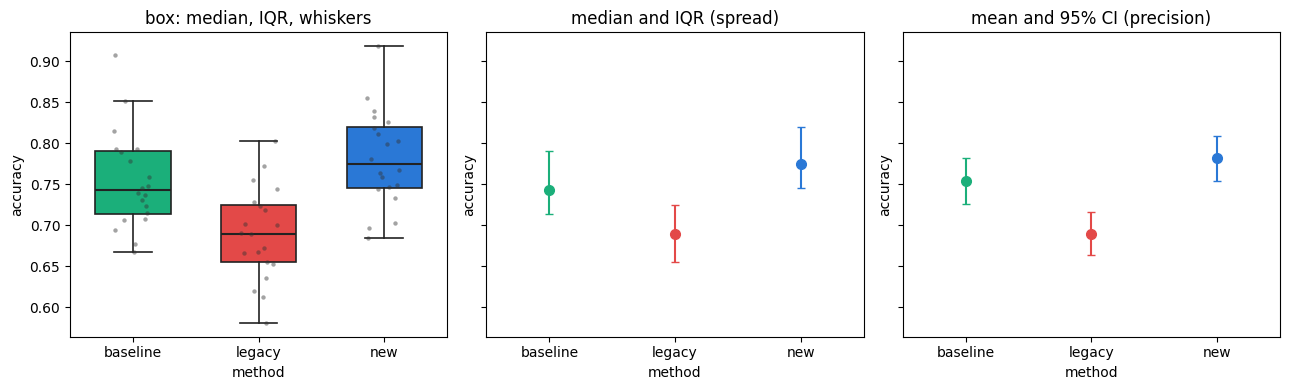

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
suite.plot.box("accuracy", x="method", unit="subject", palette=COLORS, ax=axes[0],
               title="box: median, IQR, whiskers")
suite.plot.point("accuracy", x="method", unit="subject", center="median", interval="iqr",
                 palette=COLORS, ax=axes[1], title="median and IQR (spread)")
suite.plot.point("accuracy", x="method", unit="subject", center="mean", interval="ci",
                 palette=COLORS, ax=axes[2], title="mean and 95% CI (precision)")
fig.tight_layout()

Every plot returns a `Plot`. It unpacks as `fig, ax`, and it also holds the
numbers it drew (`.data`) and its artists by layer (`.artists`), to restyle after
the fact. The CI drawn is exactly `suite.estimate.mean`'s:

In [18]:
p = suite.plot.point("accuracy", x="method", unit="subject", palette=COLORS)
plt.close(p.fig)
p.data[["method", "n", "center", "low", "high"]]

,method,n,center,low,high
0,baseline,20,0.753847,0.726131,0.781564
1,legacy,20,0.689274,0.662987,0.715561
2,new,20,0.781408,0.754063,0.808753


In [19]:
suite.estimate.mean("accuracy", group_by="method", pairing_col="subject").table

,group,estimate,ci_low,ci_high,n,ci_method
0,baseline,0.753847,0.726131,0.781564,20,t
1,legacy,0.689274,0.662987,0.715561,20,t
2,new,0.781408,0.754063,0.808753,20,t


### Group comparison

The values per method, with a bracket for each significant pair. The plot uses the
same rows as the test: one point per subject, its 3 runs averaged
(`unit_col="run"`). `kind` picks the element (`"box"`, `"violin"`, `"bar"`,
`"point"`, `"strip"`), and `annotate` the bracket text. On the right, the point
plot shows what matches a Wilcoxon test without being asked: each method's median
with its exact 95% interval.

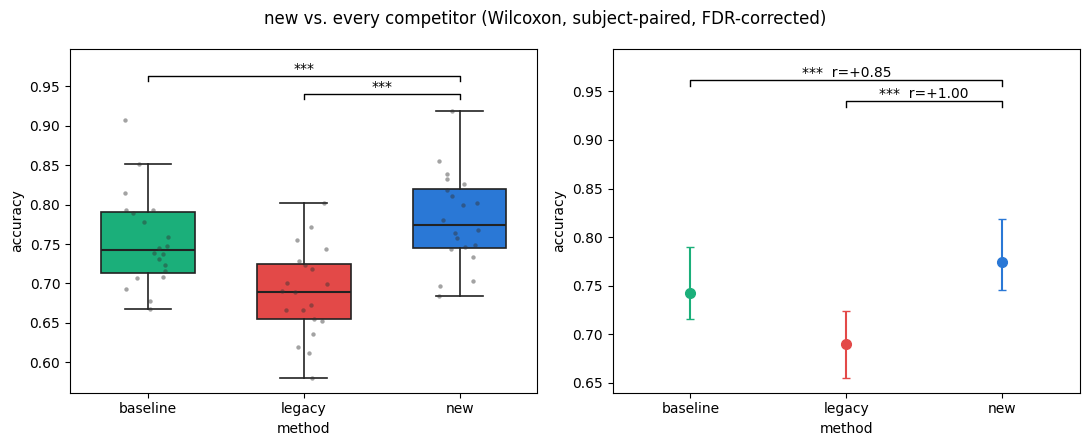

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
suite.plot.group_comparison(acc, palette=COLORS, ylabel="accuracy", ax=axes[0])
suite.plot.group_comparison(
    acc, kind="point", annotate=("stars", "effect"),
    palette=COLORS, ylabel="accuracy", ax=axes[1],
)
fig.suptitle("new vs. every competitor (Wilcoxon, subject-paired, FDR-corrected)")
fig.tight_layout()

### Paired differences

The view that matches what a paired test actually sees: one point per subject,
`new - competitor`. The black mark is the test's own estimate with its 95% interval
-- for a Wilcoxon test, the Hodges-Lehmann estimate (the same numbers as
`suite.estimate.from_result(acc)`). Annotations, top to bottom, in the order given:
significance, the first effect size (`"effect"`), win rate (share of subjects where
`new` wins, minus 50%), and any effect size the result reports, by name -- here the
Hodges-Lehmann estimate again.

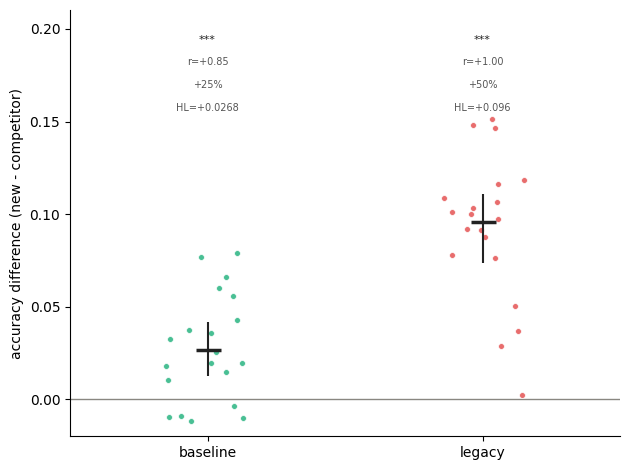

In [21]:
fig, ax = suite.plot.paired_differences(
    acc, palette=COLORS, annotate=("stars", "effect", "winrate", "hodges_lehmann"),
)
ax.set_ylabel("accuracy difference (new - competitor)")
fig.tight_layout()

With an offset, the plot draws it as a dashed line. The annotations don't change
(effect sizes ignore the offset); only the stars do. Reading the HL estimate
against the dashed line is the visual version of the offset test.

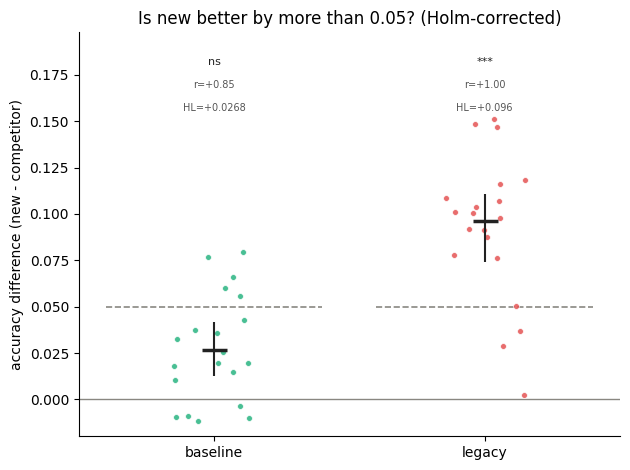

In [22]:
fig, ax = suite.plot.paired_differences(
    acc_margin, palette=COLORS, annotate=("stars", "effect", "hodges_lehmann"),
)
ax.set_ylabel("accuracy difference (new - competitor)")
ax.set_title("Is new better by more than 0.05? (Holm-corrected)")
fig.tight_layout()

### Estimates

`suite.plot.estimate` draws an `EstimateResult` as points with their intervals.
With `reference`, every difference is oriented so up means `reference` better --
here the Hodges-Lehmann estimates from Part 2, against the 0.05 offset:

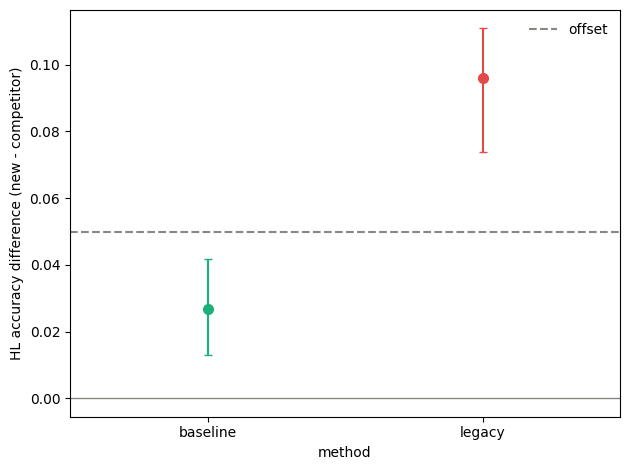

In [23]:
fig, ax = suite.plot.estimate(
    hl, reference="new", palette=COLORS, reference_lines={"offset": 0.05},
    ylabel="HL accuracy difference (new - competitor)",
)
ax.legend(frameon=False)
fig.tight_layout()

For a lower-is-better metric, `higher_is_better=False` flips the differences, so
up still means "`new` better":

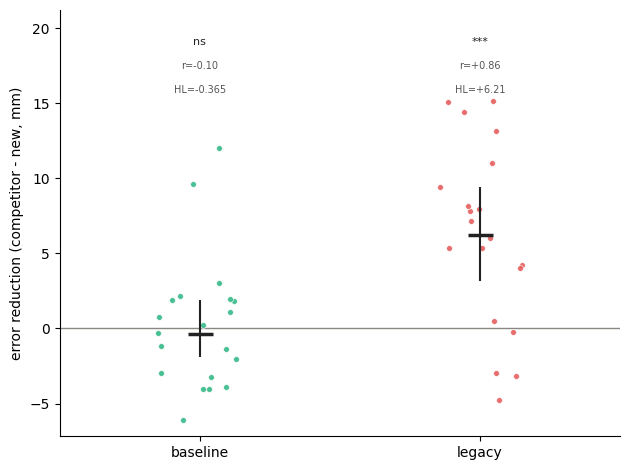

In [24]:
fig, ax = suite.plot.paired_differences(
    err, higher_is_better=False, palette=COLORS, annotate=("stars", "effect", "hodges_lehmann"),
)
ax.set_ylabel("error reduction (competitor - new, mm)")
fig.tight_layout()

## 💾 - Part 4: Saving, loading, and verifying

The suite holds the data; results are separate objects. Nothing is cached: each
`suite.stat.*` / `suite.estimate.*` call computes fresh, and you keep a result by
saving it.

### Saving and loading the suite

`suite.save(folder)` writes the data (`data.npz` + `meta.json`);
`MetricSuite.load(folder)` reads it back. We save into a temporary folder here, to
keep the repository clean.

In [25]:
workdir = Path(tempfile.mkdtemp())
suite.save(workdir / "fake_study")
reloaded = MetricSuite.load(workdir / "fake_study")
sorted(p.name for p in (workdir / "fake_study").iterdir())

MetricSuite successfully saved to folder: /tmp/tmp5iase3yd/fake_study


['data.npz', 'meta.json']

### Saving and loading results

Each result saves on its own -- e.g. to hand it to someone who doesn't have the
data, or to avoid rerunning an expensive cluster-permutation test. It keeps its
table, its settings, and its `data_key`.

In [26]:
acc.save(workdir / "accuracy_wilcoxon")
hl.save(workdir / "accuracy_hl")

acc_loaded = PairwiseResult.load(workdir / "accuracy_wilcoxon")
hl_loaded = EstimateResult.load(workdir / "accuracy_hl")
acc_loaded

PairwiseResult(metric='accuracy', test='wilcoxon', correction='fdr_bh', alpha=0.05, n_comparisons=2)
  new vs baseline: p=0.0003223*, rank_biserial=0.848, hodges_lehmann=0.0268, n=20
  new vs legacy: p=3.815e-06*, rank_biserial=1, hodges_lehmann=0.096, n=20

In [27]:
hl_loaded.vs("new")

,estimate,ci_low,ci_high,n_reference,n_competitor
method,,,,,
baseline,0.026838,0.012825,0.041904,20,20
legacy,0.096022,0.073912,0.110892,20,20


A result can always be re-corrected without rerunning anything -- `correct`
returns a new result recording the new correction:

In [28]:
acc_loaded.correct("bonferroni", alpha=0.01).vs("new")[["p_value", "p_corrected", "significant"]]

,p_value,p_corrected,significant
method,,,
baseline,0.000322,0.000645,True
legacy,0.000002,0.000004,True


### Checking that a result belongs to a suite

Once results live in files, it's easy to lose track of which data they came from.
`suite.verify(result)` compares the result's `data_key` -- a fingerprint of the
exact rows it was computed from (its metric, after its filters) -- with the same
fingerprint of the suite's current data. The fingerprint ignores row order and other
metrics, so a reloaded suite matches:

In [29]:
reloaded.verify(acc_loaded), reloaded.verify(hl_loaded)

(True, True)

A suite built from different data doesn't -- here the same study design with
another random seed:

In [30]:
other = make_study(seed=1, name="Another fake study")
other.verify(acc_loaded)

False

Registering more data for a metric changes its fingerprint, so a result computed
before no longer verifies:

In [31]:
reloaded.register("accuracy", 0.95, method="new", subject="sub-20", run=0)
reloaded.verify(acc_loaded)

False

Results for other metrics are unaffected -- `error_mm` didn't change. The same
holds when pooling batches with `MetricSuite.concat`: results on a metric only one
batch has still verify, results on a metric both batches have don't.

In [32]:
reloaded.verify(err)

True

Plots and `from_result` estimates re-read the data a result describes, so they
refuse a result that doesn't match instead of silently drawing other data:

In [33]:
try:
    other.plot.paired_differences(acc_loaded)
except ValueError as e:
    print(e)
plt.close("all")

This PairwiseResult (metric='accuracy') was computed from different data than this suite now holds -- another suite, or this one before more data was registered. Recompute it from this suite.


## Wrap-up

- `suite.register(metric, values, **coords)` -- add an output, tagged with free-form
  labels; `describe()`, `summary()`, `to_df()` to inspect.
- `suite.stat.wilcoxon` / `paired_ttest` / `ttest_ess` (paired), `ttest` /
  `mannwhitneyu` (independent) -- pick `group_by`, `comparisons`, `pairing_col`,
  `unit_col`; optional `offset`/`alternative` (p-value only), `correction`
  (`"fdr_bh"`, `"fdr_by"`, `"bonferroni"`, `"holm"`), and `effect_sizes`
  (limited to the test, see `PairwiseResult.EFFECT_SIZES`).
- `result.table` (everything), `result.vs(reference, higher_is_better)` (oriented
  view), `result.correct(...)` (re-correct without rerunning).
- `suite.estimate.<name>` -- every effect size plus `mean`/`median`, with a
  confidence interval where one exists (`ci=False` otherwise);
  `suite.estimate.from_result(result)` for the interval matching a test.
- `suite.plot.<raw view>(metric, x, hue, unit=...)` and `suite.plot.<stat view>(result)`
  -- choose `center`/`interval`, label with `labels`/`xlabel`/`ylabel`/`title`, color
  with `palette`/`fill_alpha`, restyle with `*_kws` or the returned `Plot`.
- `suite.save` / `MetricSuite.load` (data), `result.save` / `PairwiseResult.load` /
  `EstimateResult.load` (results), and `suite.verify(result)` to check where a
  result came from.